# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Pelka 2021's malignant manifold is **non-branching**: the gastrulation / somitogenesis
/ neural-crest developmental signatures form a single monotone gradient (posterior
somitogenesis high at one end; neural crest the opposite, terminal end — pSom↔Crest is
the dominant axis, spatial r≈−0.89) rather than a hub radiating to discrete subtypes. A
node-count sweep confirms it: 2 tips, **0 forks** at every node count tried. The correct
topology is therefore a **principal curve** (ElPiGraph, non-branching by construction) fit
on the *joint* embedding — **not** a re-embedding (re-embedding an anisotropic compartment
fabricates folds).

**Scope decision (derived, not inherited).** Kürten 2021 confined its developmental axis to
a low-cycling lobe and excluded the cycling lobe. That is **not** transferable here: the neural-crest
terminus sits overwhelmingly inside the **cycling** compartment (~94% of the Crest-high
decile) and the *dominant* module (posterior somitogenesis) has near-identical means in the
two compartments (pSom ≈ +0.031 in both). Restricting to the low-cycling compartment would
therefore truncate the very gradient under test, so the proliferation split is largely
**orthogonal** to the developmental axis and the whole
manifold is the honest developmental object (Lee 2020 / Bischoff / Sun no-scoping
precedent). Reported caveat: pseudotime co-varies with cycling, more weakly than with the
developmental signatures. The curve is rooted at the somitogenesis/gastrulation-high tip and
flows to the neural-crest terminus. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
We keep all cells on their *original joint embedding coordinates* — no re-embedding. The
three embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against
the shared **union** control pool and graph-smoothed (3 knn-connectivity passes) to read
geography rather than 10x per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present | mean {adata.obs[lab].mean():+.4f}')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 108979 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.30
Gast: 79/81 genes present | mean -0.0137
pSom: 94/98 genes present | mean +0.0333
Crest: 104/104 genes present | mean -0.0169


### Scope decision — whole manifold vs low-cycling lobe (data-driven)
Test whether the developmental axis is confined to the low-cycling compartment (Kürten case,
where scoping is justified) or spans both (Bischoff/Sun/Lee case, where the whole manifold
must be kept). Two facts settle it here: (i) the smoothed developmental signatures form one
axis (pSom↔Crest strongly opposed, Gast weak); (ii) the compartments have near-identical
means for the dominant module (pSom ≈ +0.031 in both) while the Crest-high terminus is
concentrated in the *cycling* compartment (~94% of its top decile) — so excluding it would
truncate the gradient under test.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-compartment smoothed developmental means:')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict()
print('\nCrest-high decile distributed across compartments:', frac)
print('-> developmental axis is orthogonal to the proliferation split; keep whole manifold (no scoping).')
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.15
  Crest_sm vs Gast_sm: r = -0.19
  Crest_sm vs pSom_sm: r = -0.89

per-compartment smoothed developmental means:
                   Gast_sm  pSom_sm  Crest_sm
compartment                                  
Cycling/Metabolic  -0.0163   0.0314   -0.0141
Embryonic          -0.0063   0.0319   -0.0185

Crest-high decile distributed across compartments: {'Cycling/Metabolic': 0.94, 'Embryonic': 0.06}
-> developmental axis is orthogonal to the proliferation split; keep whole manifold (no scoping).


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone. A node-count sweep
(15/20/30) all returned 2 tips / 0 forks with a fold self-approach ratio > 1 (minimum
distance between graph-non-adjacent nodes, in units of median edge length), so the curve is
robustly non-branching and does not fold back on itself; `Nodes=20` is the smallest count at
which the self-approach ratio is maximal. `epg_mu=100` is strong bending regularisation,
keeping the arc smooth rather than a sharp V.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, "topology check failed"

curve: 2 tips, 0 forks | fold self-approach ratio = 2.99 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental
origin. Pseudotime then flows to the neural-crest terminus. Rooting at the Crest tip or a
cycling state is explicitly avoided (developmentally, neural crest is *late*).

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0117 pSom=+0.0118 Crest=-0.0027
tip 2: Gast=-0.0086 pSom=+0.0513 Crest=-0.0288
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho):
  Gast_sm: rho=-0.249 p=0.0e+00
  pSom_sm: rho=-0.788 p=0.0e+00
  Crest_sm: rho=+0.831 p=0.0e+00
  cyc_score: rho=+0.070 p=4.5e-119


### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates (discrete sign choice, no rotation — an SVD basis can
silently reflect an axis). This trajectory is already **horizontal** in the raw embedding, so
the house transform is the **identity** (X_umap_lin = raw_umap). The assertion confirms low
pseudotime lands on the left.

In [7]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])        # identity: already horizontal
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:                                         # ensure low pt -> left
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: identity (already horizontal); corr(x_lin, pseudotime) = {r:+.2f}')

orientation: identity (already horizontal); corr(x_lin, pseudotime) = +0.98


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


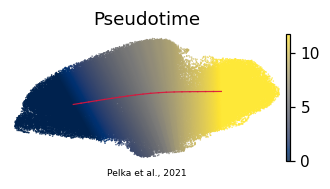

In [8]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=4, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
# overlay fitted curve edges to catch folds (rendered, not just metric-checked)
F = sub.uns['graph']['F'].T; B = np.asarray(sub.uns['graph']['B'])
# map node positions into the linear (identity/possible-flip) frame
sgn = 1 if r>0 else -1
Fx = F[:,0]*(np.sign(np.corrcoef(sub.obsm['X_umap'][:,0], t)[0,1]))
for i in range(B.shape[0]):
    for j in range(i+1, B.shape[0]):
        if B[i,j]>0: ax.plot([Fx[i],Fx[j]],[F[i,1],F[j,1]], '-', color='crimson', lw=.8, alpha=.9)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Pelka et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')